# Phototropic transduction fit (Fig. 2C) — "Nonlinear distributed sensing of light patterns leads to perceptual distortions in plants"

**Paper**: PNAS 123(39):e2614473123 (2026), DOI [10.1073/pnas.2614473123](https://doi.org/10.1073/pnas.2614473123) — "Nonlinear distributed sensing of light patterns leads to perceptual distortions in plants."

**Data & code**: Zenodo record [10.5281/zenodo.21206480](https://zenodo.org/records/21206480) (concept 19110266, version published 2026-07-05, CC-BY-4.0), single archive `multiple_light_integration_final.zip` (11,728,994 bytes, MD5 `06d911cc56c6cf92d66af15304bb93f9`).

**Scope of this notebook** (one minimal, faithful demonstration):
1. Download and checksum-verify the pinned Zenodo archive inside Colab.
2. Derive steady-state tip angles $\theta_f$ from the deposited trajectory spreadsheet (`00_Data/uni_trajectories.csv`) exactly as in the authors' `01_Preprocessing/02_Uni_cleanup.py`.
3. Refit the phototropic transduction function ($\sin\theta_f$ vs $I\cos\theta_f$, power law $y=A\,x^{\alpha}$ by orthogonal distance regression) as in the authors' `02_Analysis/02_Unilateral_light.ipynb`, and recover the paper's reported $\nu_0/\beta = 0.71$ and $\alpha = 0.30$ (Fig. 2C).

**Not in scope**: raw-image re-tracking, YOLOv8 segmentation, bilateral/three-light and simulation studies.

**Runtime**: CPU only — this is a small tabular regression; no GPU is required. Expected total time is a few minutes with ~12 MB of downloads.

**実行環境**： CPU のみで動作します（小規模な表データの回帰のため GPU は不要）。数分・約 12 MB のダウンロードで完結します。


## How to run / 実行方法

Select **Runtime → Change runtime type → CPU** (the default is fine), then **Runtime → Run all**.
The notebook downloads the authors' Zenodo archive, verifies its integrity, and reproduces the Fig. 2C fit end to end. No credentials, Drive mount, or GPU is needed.

**ランタイム → すべてのセルを実行** で実行できます。認証情報や Google Drive、GPU は不要です。


## Environment setup / 環境セットアップ

All scientific dependencies (NumPy, pandas, SciPy, matplotlib) are preinstalled on Colab.
The cell below imports them and prints the runtime environment actually used for this execution (Python version and, for the record, whether a GPU is visible — none is needed).

**依存関係は Colab に既導入の NumPy / pandas / SciPy / matplotlib のみ。実行環境の情報を表示します。**

In [ ]:
import platform, sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("numpy:", np.__version__, "| pandas:", pd.__version__,
      "| scipy:", scipy.__version__, "| matplotlib:", matplotlib.__version__)
try:
    import torch
    print("torch.cuda.is_available():", torch.cuda.is_available(), "(not required for this reproduction)")
except ImportError:
    print("torch not installed (not required for this reproduction)")

Python: 3.13.16
numpy: 2.1.3 | pandas: 2.2.3 | scipy: 1.16.3 | matplotlib: 3.10.0


torch.cuda.is_available(): False (not required for this reproduction)


## Data acquisition with pinned provenance / データ取得（改変なしの完全性検証つき）

Download the authors' archive from the **exact version record** (Zenodo 21206480) using its documented file-content API endpoint, then verify the byte size and MD5 against the values published in the record metadata. The download is aborted unless both match.

**Zenodo のバージョン記録 21206480 からアーカイブを取得し、公開されているサイズと MD5 が一致しない場合は中断します。**

In [ ]:
import urllib.request, hashlib, os

ZENODO_CONTENT = ("https://zenodo.org/api/records/21206480/files/"
                  "multiple_light_integration_final.zip/content")
EXPECTED_MD5 = "06d911cc56c6cf92d66af15304bb93f9"
EXPECTED_SIZE = 11728994  # bytes, from the Zenodo record metadata

os.makedirs("/content/zenodo", exist_ok=True)
zip_path = "/content/zenodo/multiple_light_integration_final.zip"
urllib.request.urlretrieve(ZENODO_CONTENT, zip_path)

size = os.path.getsize(zip_path)
md5 = hashlib.md5()
with open(zip_path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
        md5.update(chunk)

print(f"downloaded: {size:,} bytes (expected {EXPECTED_SIZE:,})")
print(f"md5: {md5.hexdigest()} (expected {EXPECTED_MD5})")
assert size == EXPECTED_SIZE, "size mismatch — download is not the pinned artifact"
assert md5.hexdigest() == EXPECTED_MD5, "md5 mismatch — download is not the pinned artifact"
print("VERIFIED: archive matches the pinned Zenodo record 21206480")

downloaded: 11,728,994 bytes (expected 11,728,994)
md5: 06d911cc56c6cf92d66af15304bb93f9 (expected 06d911cc56c6cf92d66af15304bb93f9)
VERIFIED: archive matches the pinned Zenodo record 21206480


Extract **only the members needed for the Fig. 2C refit** from the verified archive (the trajectory spreadsheet, the authors' precomputed steady-state table, and the light-transmittance measurements). All archive bytes stay under `/content` on the Colab VM.

**検証済みアーカイブから Fig. 2C の再計算に必要な 3 つのファイルのみ展開します。**

In [ ]:
import zipfile

MEMBERS = [
    "00_Data/uni_trajectories.csv",          # extracted tip-angle trajectories (per plant)
    "00_Data/uni_stst_angles.csv",           # authors' precomputed steady-state angles (Fig. 2C input)
    "07_Supplementary/T_measurements_data.csv",  # tissue light-transmittance measurements
]

with zipfile.ZipFile(zip_path) as zf:
    names = set(zf.namelist())
    for member in MEMBERS:
        assert member in names, f"{member} missing from archive"
        zf.extract(member, "/content/zenodo/extracted")
    print("extracted:", *MEMBERS, sep="\n  ")

TRAJ_CSV = "/content/zenodo/extracted/00_Data/uni_trajectories.csv"
STST_CSV = "/content/zenodo/extracted/00_Data/uni_stst_angles.csv"
T_CSV = "/content/zenodo/extracted/07_Supplementary/T_measurements_data.csv"


extracted:
  00_Data/uni_trajectories.csv
  00_Data/uni_stst_angles.csv
  07_Supplementary/T_measurements_data.csv


## Input preview — tip-angle trajectories / 入力データの確認

Before any analysis, preview the actual input: mean tip angle $\theta_{tip}$ over time for each blue-light intensity, with the steady-state window (16–21 h) used by the authors shaded. This mirrors the authors' Fig. 2B panel (`02_Analysis/02_Unilateral_light.ipynb`) but uses simple matplotlib defaults; it is a data preview, not a reproduction of the published figure styling.

The `theta` column is in **degrees**, `dt` is time in **hours**, and `light_i` is the unilateral light intensity in **W/m²**.

**入力データの確認： 各光強度の時間経過に伴う頂点角度の平均（陰影は標準誤差）。灰色の帯は 16–21 h の定常状態ウィンドウです。**

dt         float64
theta      float64
light_i    float64
real_id     object
dtype: object
rows: 88,504 | plants (real_id): 268 | intensities: [np.float64(0.7), np.float64(1.1), np.float64(1.4), np.float64(1.9), np.float64(2.25), np.float64(3.0), np.float64(3.2), np.float64(3.85), np.float64(4.4), np.float64(5.8)]


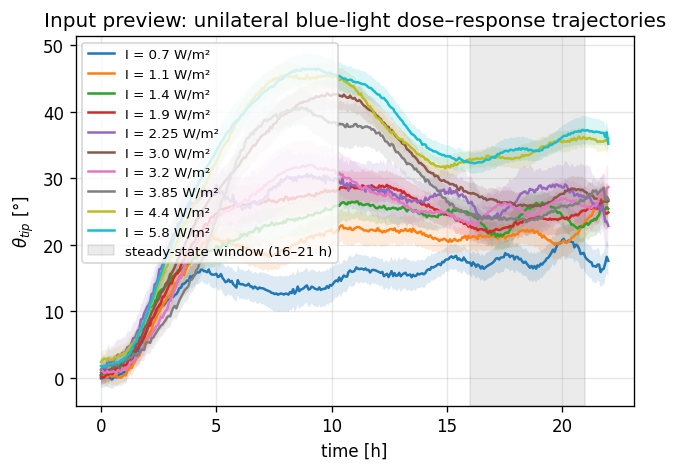

In [ ]:
traj = pd.read_csv(TRAJ_CSV)
print(traj.dtypes)
print(f"rows: {len(traj):,} | plants (real_id): {traj['real_id'].nunique()} | "
      f"intensities: {sorted(traj['light_i'].unique())}")

df_mean = (traj.groupby(["light_i", "dt"], as_index=False)
           .agg(theta_mean=("theta", "mean"), theta_std=("theta", "std"), n=("theta", "count")))

fig, ax = plt.subplots(figsize=(6, 4), dpi=120)
for light, group in df_mean.groupby("light_i"):
    ax.plot(group["dt"], group["theta_mean"], label=f"I = {light} W/m²")
    ax.fill_between(group["dt"],
                    group["theta_mean"] - group["theta_std"] / np.sqrt(group["n"]),
                    group["theta_mean"] + group["theta_std"] / np.sqrt(group["n"]),
                    alpha=0.15)
ax.axvspan(16, 21, color="k", alpha=0.08, label="steady-state window (16–21 h)")
ax.set_xlabel("time [h]"); ax.set_ylabel(r"$\theta_{tip}$ [°]")
ax.set_title("Input preview: unilateral blue-light dose–response trajectories")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

## Steady-state angles $\theta_f$ from the trajectories / 軌道データから定常状態角度を導出

Re-implement the authors' `01_Preprocessing/02_Uni_cleanup.py` (ported verbatim except for paths, which are Linux Colab paths here): for each plant (`real_id`) at each intensity, average `theta` over the steady-state window `16 h ≤ dt < 21 h`; then report the per-intensity mean and standard deviation **in radians** and the plant count N. Intensities above 7 W/m² are excluded as light-saturation points, exactly as in the authors' script.

**著者の `02_Uni_cleanup.py` をそのまま移植（パスのみ変更）： 各植物の 16–21 h 平均角度から強度ごとの平均・標準偏差（ラジアン）と N を求め、7 W/m² 超の飽和点を除外します。**

In [ ]:
SS_LOW, SS_HIGH = 16, 21   # steady-state window in hours (authors: dt >= 16 and dt < 21)
I_MAX = 7                  # exclude light-saturation points above 7 W/m² (authors' filter)

theta_f_rows = []
for intens in sorted(traj["light_i"].unique())[::-1]:
    curr_df = traj[traj["light_i"] == intens]
    stst_angles = []
    for real_id in curr_df["real_id"].unique():
        tip_df = curr_df[curr_df["real_id"] == real_id]
        stst_angle_df = tip_df[(tip_df["dt"] >= SS_LOW) & (tip_df["dt"] < SS_HIGH)]
        stst_angles.append(stst_angle_df["theta"].mean())
    theta_f_rows.append({
        "intensity_W_m2": intens,
        "mean_angle_rad": np.deg2rad(np.mean(stst_angles)),
        "std_angle_rad": np.deg2rad(np.std(stst_angles)),
        "N": len(stst_angles),
    })

theta_f_derived = pd.DataFrame(theta_f_rows).reset_index(drop=True)
theta_f_derived = theta_f_derived[theta_f_derived["intensity_W_m2"] <= I_MAX]  # authors' saturation filter
print(theta_f_derived)

   intensity_W_m2  mean_angle_rad  std_angle_rad   N
0            5.80        0.602476       0.149133  31
1            4.40        0.595892       0.103141  25
2            3.85        0.429510       0.137045  20
3            3.20        0.444372       0.188016  22
4            3.00        0.469271       0.160002  33
5            2.25        0.469618       0.196580  15
6            1.90        0.408179       0.215863  33
7            1.40        0.416676       0.154897  28
8            1.10        0.372370       0.191226  32
9            0.70        0.316837       0.170581  29


Cross-check the derived table against the authors' precomputed `00_Data/uni_stst_angles.csv` shipped in the deposit. Agreement confirms that the derivation above reproduces the authors' pipeline; the **authors' precomputed table is then used for the fit**, exactly as in their notebook.

**導出結果を deposit 同梱の事前計算表と照合します（一致すれば導出パイプラインの再現を確認）。フィットには著者の表をそのまま使用します。**

In [ ]:
stst_authors = pd.read_csv(STST_CSV)
print("authors' precomputed table:")
print(stst_authors)

merged = theta_f_derived.merge(stst_authors, on="intensity_W_m2", suffixes=("_derived", "_authors"))
max_diff = (merged["mean_angle_rad_derived"] - merged["mean_angle_rad_authors"]).abs().max()
print(f"\nmax |mean_angle_rad derived − authors| = {max_diff:.2e} rad over {len(merged)} intensities")
assert max_diff < 1e-8, "derived steady-state angles disagree with the authors' table"
print("CHECK PASSED: derived theta_f matches the authors' precomputed uni_stst_angles.csv")

# Use the authors' table for the fit (their notebook loads this file directly).
intensity = stst_authors["intensity_W_m2"].values
angle = stst_authors["mean_angle_rad"].values
angle_STD = stst_authors["std_angle_rad"].values
N = stst_authors["N"].values
angle_STE = angle_STD / np.sqrt(N)  # standard error of the mean

authors' precomputed table:
   intensity_W_m2  mean_angle_rad  std_angle_rad   N
0            5.80        0.602476       0.149133  31
1            4.40        0.595892       0.103141  25
2            3.85        0.429510       0.137045  20
3            3.20        0.444372       0.188016  22
4            3.00        0.469271       0.160002  33
5            2.25        0.469618       0.196580  15
6            1.90        0.408179       0.215863  33
7            1.40        0.416676       0.154897  28
8            1.10        0.372370       0.191226  32
9            0.70        0.316837       0.170581  29

max |mean_angle_rad derived − authors| = 1.11e-16 rad over 10 intensities
CHECK PASSED: derived theta_f matches the authors' precomputed uni_stst_angles.csv


## Tissue transmittance check / 組織透過率の確認

The paper reports a transmission factor $T = 9.8\% \pm 4.2\%$ (N = 31, Materials and Methods). The authors' `07_Supplementary/T_measurments.py` computes it from `T_measurements_data.csv`; run the same computation to confirm the measured value (the fit itself uses the authors' hardcoded $T=0.1$, as in their notebook cell).

**著者のスクリプトと同じ計算で T ≈ 9.8% (N=31) を確認します。フィット自体は著者コードと同様に T = 0.1 を使用します。**

In [ ]:
t_data = pd.read_csv(T_CSV)
t_data["percent"] = t_data["w_plant"] / t_data["clear"] * 100
print(f"mean T = {t_data['percent'].mean():.1f}%")
print(f"std = {t_data['percent'].std():.1f}%")
print(f"ste = {t_data['percent'].std()/np.sqrt(len(t_data)):.1f}%")
print("N =", len(t_data))

mean T = 9.8%
std = 4.2%
ste = 0.8%
N = 31


## Fig. 2C transduction fit — $\sin\theta_f$ vs $I\cos\theta_f$ / 光伝達関数のフィット

Port of the authors' fit cells (`02_Analysis/02_Unilateral_light.ipynb`, cells 9–14):
- $X = I\cos(\theta_f)$, $Y = \sin(\theta_f)$
- Light-measurement uncertainty $\mathrm{d}I = 0.06$ W/m² (STD reported by the authors); angle uncertainty = SEM of $\theta_f$
- $\mathrm{d}X = \sqrt{(\cos\theta_f\,\mathrm{d}I)^2 + (I\sin\theta_f\,\mathrm{d}\theta_f)^2}$, $\mathrm{d}Y = \cos\theta_f\,\mathrm{d}\theta_f$
- Orthogonal distance regression (ODR, as in the authors' code) of $Y = A\,X^{\alpha}$ with start vector $\beta_0=[0.1, 0.1]$

$R^2$ is computed with the standard definition ($1 - SS_{res}/SS_{tot}$), which is exactly what the authors' `sklearn.metrics.r2_score` computes.

**著者のセル 9–14 を移植： X = I cos θf, Y = sin θf とその不確かさを伝播し、直交距離回帰（ODR）でべき乗則 Y = A·X^α をフィットします。**

In [ ]:
from scipy.odr import ODR, Model, RealData

X = intensity * np.cos(angle)  # I · cos(theta_f)  [W/m²]
Y = np.sin(angle)              # sin(theta_f)

dI = 0.06  # STD of light measurements [W/m²], authors' value
dX = np.sqrt((np.cos(angle) * dI) ** 2 + (intensity * np.sin(angle) * angle_STE) ** 2)
dY = np.cos(angle) * angle_STE

def power_law_func(beta, x):
    y = beta[0] * x ** beta[1]
    return y

my_model = Model(power_law_func)
my_data = RealData(X, Y, sx=dX, sy=dY)
my_odr = ODR(my_data, my_model, beta0=[0.1, 0.1])
my_odr.set_job()
out = my_odr.run()

A, alpha = out.beta
ss_res = np.sum((Y - power_law_func(out.beta, X)) ** 2)
ss_tot = np.sum((Y - np.mean(Y)) ** 2)
r2 = 1 - ss_res / ss_tot  # == sklearn.metrics.r2_score

print(f"ODR fit parameters: A={A:.3g}, alpha={alpha:.3g}")
print(f"R2 = {r2:.3f}")
print(f"Residual variance = {out.res_var:.3g}")
print(f"param uncertainty A, alpha = {out.sd_beta}")

ODR fit parameters: A=0.352, alpha=0.297
R2 = 0.726
Residual variance = 2.76
param uncertainty A, alpha = [0.02525546 0.06074834]


Convert the fitted prefactor into the paper's reported ratio using the authors' formula (their notebook cell 14): with transmission factor $T = 0.1$,

$$\frac{\nu_0}{\beta} = \frac{A}{1 - T^{\alpha}}$$

The paper reports $\nu_0/\beta = 0.71$ and $\alpha = 0.30$ (Results, "Estimation of Phototropic Transduction Function ν(I)"; the cell prints the difference from those reference values).

**著者の式 $\nu_0/\beta = A/(1-T^{\alpha})$（T = 0.1）で論文報告値 0.71 と α = 0.30 との一致を確認します。**

In [ ]:
T = 0.1  # authors' hardcoded transmission factor

nu_0_beta = A / (1 - T ** alpha)
print(f"nu_0/beta = {nu_0_beta:.2f}   (paper: 0.71)")
print(f"alpha     = {alpha:.2f}   (paper: 0.30)")

results = pd.DataFrame({
    "quantity": ["A (fit prefactor)", "alpha (fit power)", "nu_0/beta (T=0.1)", "R2"],
    "this_notebook": [A, alpha, nu_0_beta, r2],
    "paper_reported": [np.nan, 0.30, 0.71, np.nan],
})
results.to_csv("/content/fig2c_fit_results.csv", index=False)
print("\nresults saved to /content/fig2c_fit_results.csv")

nu_0/beta = 0.71   (paper: 0.71)
alpha     = 0.30   (paper: 0.30)

results saved to /content/fig2c_fit_results.csv


## Fig. 2C-style plot / Fig. 2C 相当のプロット

Plot the experimental points with their propagated error bars, the ODR power-law fit (log–log axes, as in the authors' figure), and print the fitted law. This reproduces the authors' Fig. 2C panel content from the deposited data; styling uses matplotlib defaults rather than the authors' `noto_sans_12pt.mplstyle`.

**実験点（誤差バー付き）と ODR フィット曲線を両対数で描画します（Fig. 2C の内容の再現、スタイルは matplotlib 既定）。**

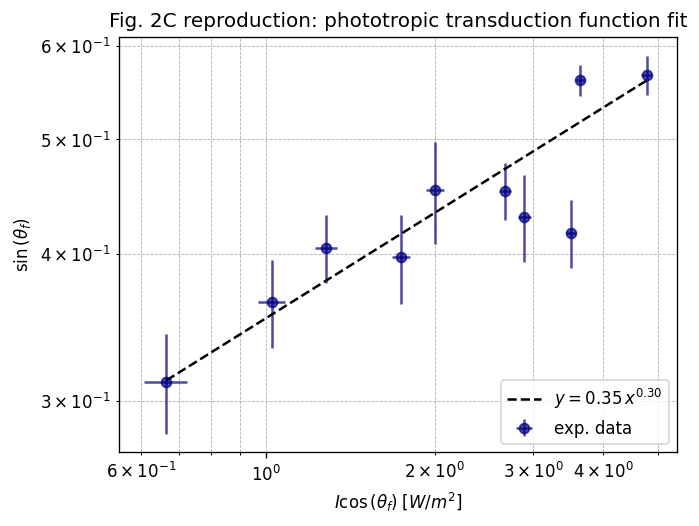

In [ ]:
x_fit = np.linspace(X.min(), X.max(), 100)
y_fit = power_law_func(out.beta, x_fit)

fig, ax = plt.subplots(figsize=(6, 4.5), dpi=120)
ax.errorbar(X, Y, yerr=dY, xerr=dX, fmt="o", label="exp. data", color="navy", alpha=0.7)
ax.plot(x_fit, y_fit, label=f"$y = {A:.2f}\\,x^{{{alpha:.2f}}}$", color="k", linestyle="--")
ax.set_xlabel(r"$I\cos{(\theta_f)}\;[W/m^2]$")
ax.set_ylabel(r"$\sin{(\theta_f)}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.grid(which="both", linestyle="--", linewidth=0.5)
ax.legend(loc="lower right")
ax.set_title("Fig. 2C reproduction: phototropic transduction function fit")
plt.show()

## Interpretation & provenance / 解釈と出典

- **Expected result**: the ODR fit recovers $\alpha \approx 0.30$ and $\nu_0/\beta \approx 0.71$ with $T=0.1$, matching the paper's Fig. 2C values (Results, "Estimation of Phototropic Transduction Function ν(I)": "Substituting the measured value of the transmission factor T=0.1 ... yields the prefactor ν0/β=0.71 ... and the power α=0.30").
- **Provenance**: all inputs come from Zenodo record [21206480](https://zenodo.org/records/21206480) (`multiple_light_integration_final.zip`, MD5-verified above); the derivation and fit follow the authors' `01_Preprocessing/02_Uni_cleanup.py` and `02_Analysis/02_Unilateral_light.ipynb` (cells 9–16), ported with path changes only and documented inline. The transmittance check follows `07_Supplementary/T_measurments.py`.
- **Adaptations (AI-authored glue, not author code)**: Linux paths instead of the authors' Windows relative paths; `r2_score` replaced by its defining formula; matplotlib default styling instead of `noto_sans_12pt.mplstyle` / `colormap_helper.py` (cosmetic only); a small number of extra `print`/`assert` checks. No scientific parameter, formula, filter, or fitting choice was altered.
- **Limitations**: this reproduces one figure-level analysis on the authors' deposited extracted data. It does not re-track raw videos, retrain any model, or verify dataset-level statistics; the deposited `theta` values themselves derive from the authors' CSRT tracking pipeline (Movie S1).

**期待される結果**： ODR フィットは論文報告値（ν0/β ≈ 0.71, α ≈ 0.30）を再現します。入力は MD5 検証済みの Zenodo デポジット、手順は著者コードの移植（パス変更と装飾のみ変更）です。生動画の再トラッキングやモデル学習は対象外です。
